In [76]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sb 

In [77]:
df_visual = pd.read_csv('exported_churn_data.csv')
df_visual.head()
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'comment',
       'complain_count'],
      dtype='object')

In [78]:
# Monthely Churn Trend(Time series KPI)
df_visual.columns
df_visual['cancellation_date'] = pd.to_datetime(df_visual['cancellation_date'])
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

In [79]:
churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()
churn_trend

cancellation_month
2024-02    1
2024-05    1
2024-09    2
2024-10    1
2024-11    1
Freq: M, dtype: int64

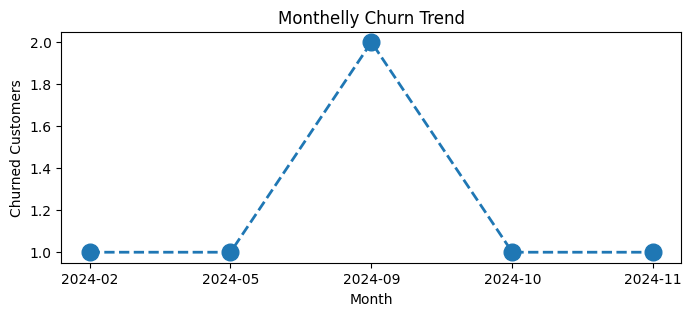

In [80]:
#Set canvas size
plt.figure(figsize=(8, 3))

#Plot the graph
plt.plot(churn_trend.index.astype(str), churn_trend.values, marker='o', linestyle='dashed',
         linewidth=2, markersize=12)

#Give titles
plt.title('Monthelly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

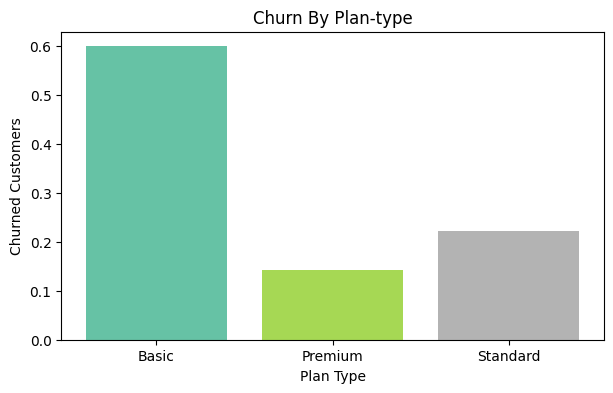

In [81]:
#Churn By Plan Type
df_visual.head(2)
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# color = ['blue', 'red', 'pink']
color = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))  #Generate random as per values

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color=color)

plt.title('Churn By Plan-type')
plt.xlabel('Plan Type')
plt.ylabel('Churned Customers')
plt.show()


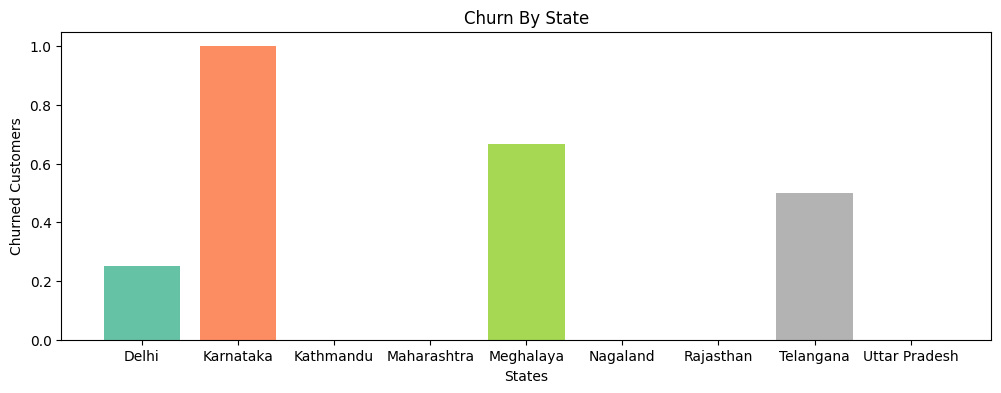

In [82]:
#Churn By State
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# color = ['blue', 'red', 'pink']
color = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))  #Generate random as per values

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color=color)

plt.title('Churn By State')
plt.xlabel('States')
plt.ylabel('Churned Customers')
plt.show()

In [83]:
#Visualization Using Seaborn
#1. HeatMap(Correlation matrix)
df_encode = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'escalations']] #Encodeing: Str to Number

df_encode.head()

,plan_type,contract_type,churn_score,churn_flag,escalations
0,Standard,Annual,12,0,NaN
1,Premium,Annual,91,1,Y
2,Basic,Monthly,34,0,NaN
3,Premium,Annual,8,0,NaN
4,Standard,Monthly,88,1,Y


In [84]:
import warnings
warnings.filterwarnings("ignore")

categorial_cols = ['plan_type', 'contract_type', 'escalations']

for col in categorial_cols:
    df_encode[col] = df_encode[col].astype('category').cat.codes
    
df_encode.head()

,plan_type,contract_type,churn_score,churn_flag,escalations
0,2,0,12,0,-1
1,1,0,91,1,1
2,0,1,34,0,-1
3,1,0,8,0,-1
4,2,1,88,1,1


Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'comment',
       'complain_count', 'cancellation_month'],
      dtype='object')

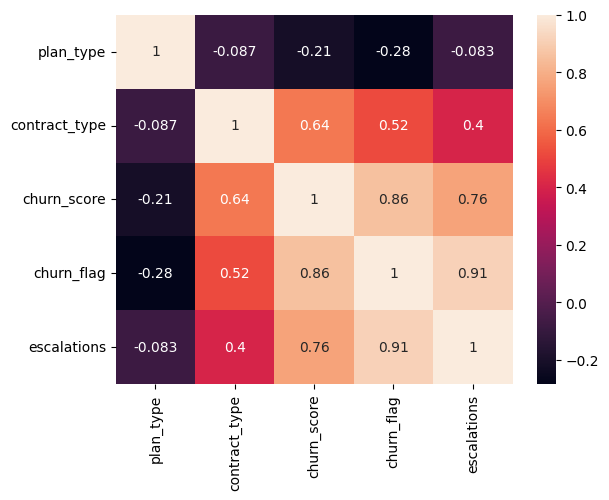

In [85]:
sb.heatmap(df_encode.corr(), annot=True)
df_visual.columns

In [86]:
#Correct method of encoding - based on priority
df_encode = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'escalations']] #Encodeing: Str to Number

order_mapping = {
    'plan_type': ['Basic', 'Standard', 'Premium'], 
    'contract_type': ['Monthly', 'Annual'], 
    'escalations': ['Y', 'N']}

for col, order in order_mapping.items():
    df_encode[col] = pd.Categorical(df_encode[col].astype('category'), categories=order, ordered=True).codes
    
df_encode.head()

,plan_type,contract_type,churn_score,churn_flag,escalations
0,1,1,12,0,-1
1,2,1,91,1,0
2,0,0,34,0,-1
3,2,1,8,0,-1
4,1,0,88,1,0


array([nan, 'Y', 'N'], dtype=object)

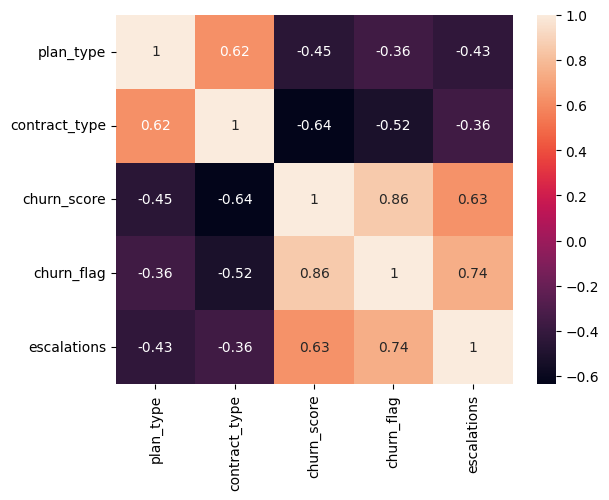

In [87]:
sb.heatmap(df_encode.corr(), annot=True)
df_visual['escalations'].unique()

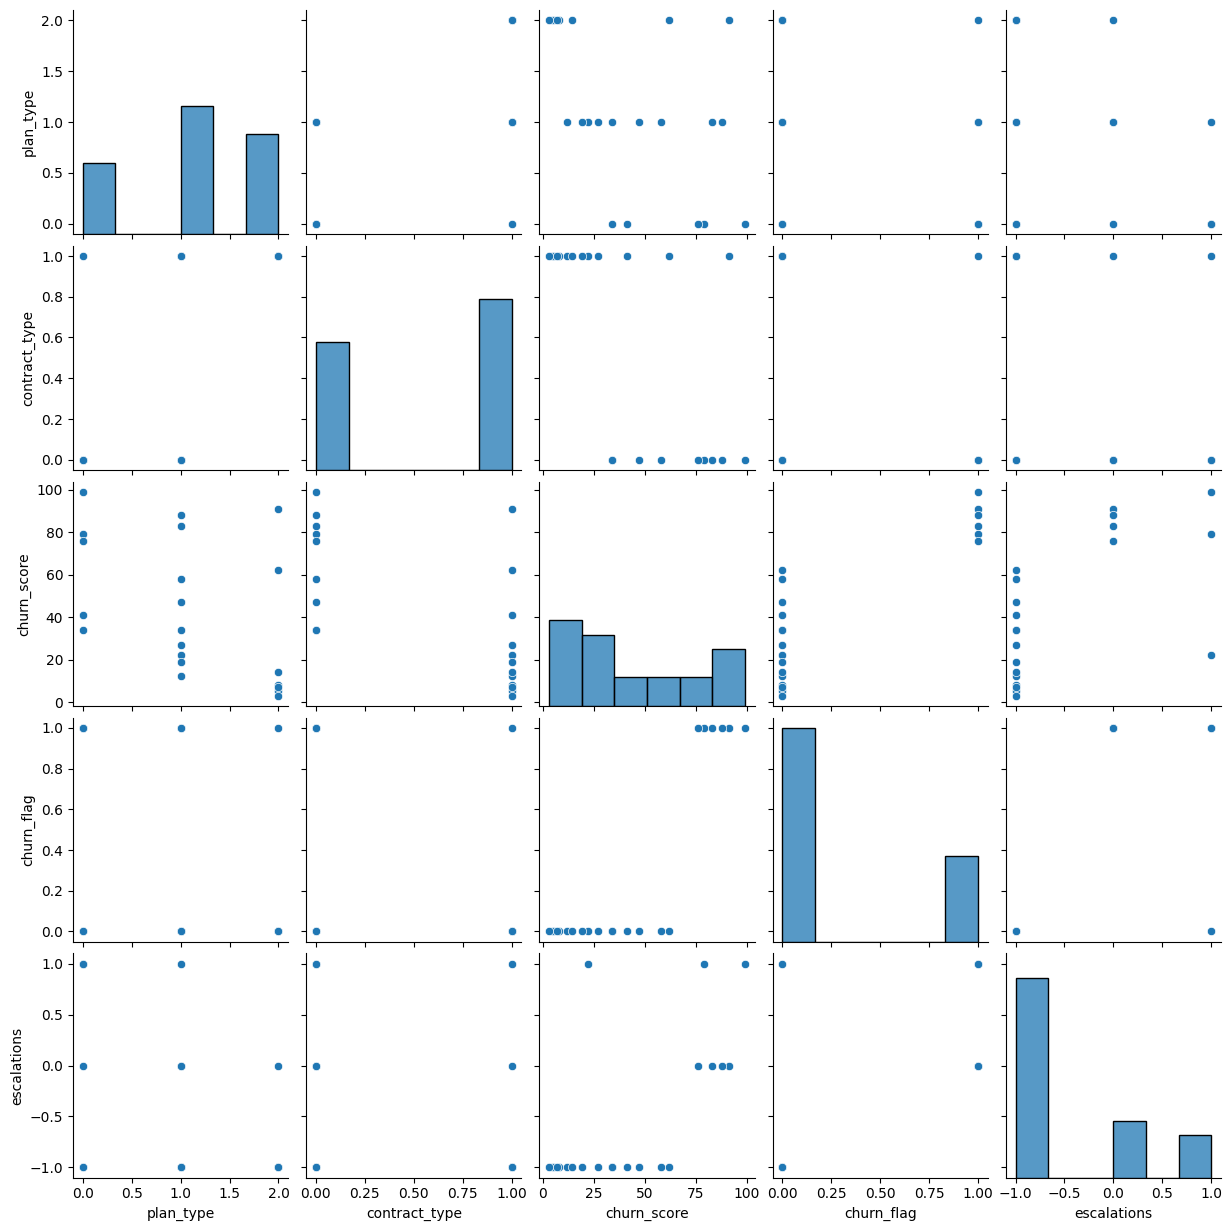

In [89]:
#2. PairPlot
sb.pairplot(df_encode)

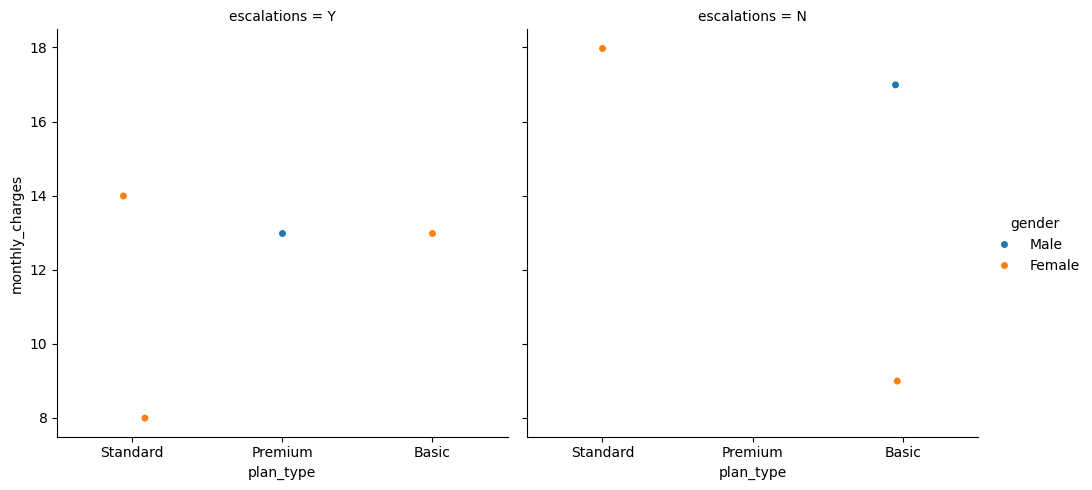

In [96]:
#Categorical/Facegrid Plot: Multi dimention comparision
# df_visual.columns
sb.catplot(data=df_visual,
    x= 'plan_type',
    y= 'monthly_charges',
    hue='gender',
    col='escalations')

In [99]:
#Pivot table
pd.pivot_table(
    df_visual, 
    values='churn_flag',
    index='plan_type',
    aggfunc='mean'
)#.reset_index()

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [101]:
pd.pivot_table(
    df_visual, 
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc={'monthly_charges': 'sum',
             'customerid':'nunique',
             'churn_flag':'mean'}
)#.reset_index()

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
